In [3]:
#Câu 1
print("Phạm Đức Anh - 6451071001")

# Khai báo các thư viện cần thiết
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

# Đọc dữ liệu từ file bank.csv (ngăn cách bằng dấu chấm phẩy ';')
df = pd.read_csv('bank.csv', sep=';')

# 1. Xem xét cấu trúc, kiểu dữ liệu và số lượng giá trị non-null của các cột
print("--- Thông tin cấu trúc dữ liệu (info) ---")
df.info()

# 2. Thống kê mô tả các thuộc tính định lượng (count, mean, std, min, tứ phân vị, max)
print("\n--- Thống kê mô tả các cột số (describe) ---")
print(df.describe())

# 3. Xem 12 dòng dữ liệu đầu tiên
df.head(12)

Phạm Đức Anh - 6451071001
--- Thông tin cấu trúc dữ liệu (info) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB

--- Thống kê mô tả các cột số 

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no
5,35,management,single,tertiary,no,747,no,no,cellular,23,feb,141,2,176,3,failure,no
6,36,self-employed,married,tertiary,no,307,yes,no,cellular,14,may,341,1,330,2,other,no
7,39,technician,married,secondary,no,147,yes,no,cellular,6,may,151,2,-1,0,unknown,no
8,41,entrepreneur,married,tertiary,no,221,yes,no,unknown,14,may,57,2,-1,0,unknown,no
9,43,services,married,primary,no,-88,yes,yes,cellular,17,apr,313,1,147,2,failure,no


In [6]:
# Câu 2
print("Phạm Đức Anh - 6451071001")

# Chuyển các giá trị 'unknown' thành NaN để thống kê dữ liệu thiếu
df_check = df.replace('unknown', np.nan)

total = df_check.isnull().sum().sort_values(ascending=False)
percent_1 = df_check.isnull().sum() / df_check.isnull().count() * 100
percent_2 = (round(percent_1, 1)).sort_values(ascending=False)
missing_data = pd.concat([total, percent_2], axis=1, keys=['Total', '%'])

print("--- Danh sách 5 thuộc tính có nhiều giá trị thiếu ('unknown') nhất ---")
print(missing_data.head(5))

Phạm Đức Anh - 6451071001
--- Danh sách 5 thuộc tính có nhiều giá trị thiếu ('unknown') nhất ---
           Total     %
poutcome    3705  82.0
contact     1324  29.3
education    187   4.1
job           38   0.8
age            0   0.0


Phạm Đức Anh - 6451071001


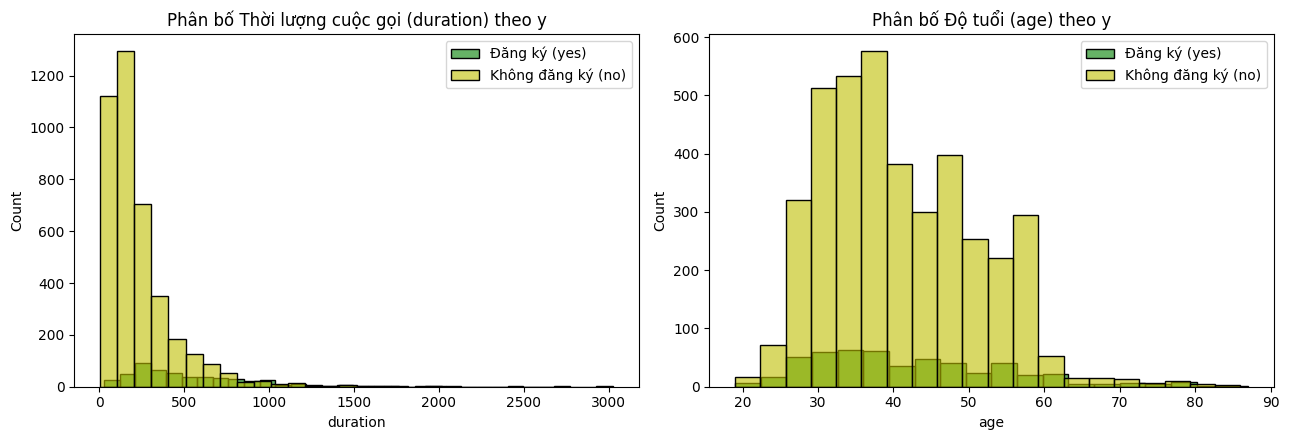

In [7]:
# Câu 3
print("Phạm Đức Anh - 6451071001")

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(13, 4.5))

# 1. Phân bố thời lượng cuộc gọi (duration) theo kết quả đăng ký (y)
sns.histplot(df[df['y'] == 'yes']['duration'], bins=30, label='Đăng ký (yes)', ax=axes[0], color='g', alpha=0.6)
sns.histplot(df[df['y'] == 'no']['duration'], bins=30, label='Không đăng ký (no)', ax=axes[0], color='y', alpha=0.6)
axes[0].legend()
axes[0].set_title('Phân bố Thời lượng cuộc gọi (duration) theo y')

# 2. Phân bố độ tuổi (age) theo kết quả đăng ký (y)
sns.histplot(df[df['y'] == 'yes']['age'], bins=20, label='Đăng ký (yes)', ax=axes[1], color='g', alpha=0.6)
sns.histplot(df[df['y'] == 'no']['age'], bins=20, label='Không đăng ký (no)', ax=axes[1], color='y', alpha=0.6)
axes[1].legend()
axes[1].set_title('Phân bố Độ tuổi (age) theo y')

plt.tight_layout()
plt.show()

Phạm Đức Anh - 6451071001


/tmp/ipykernel_449/232831170.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='education', y='y_num', data=df, ax=axes[1], palette='muted')


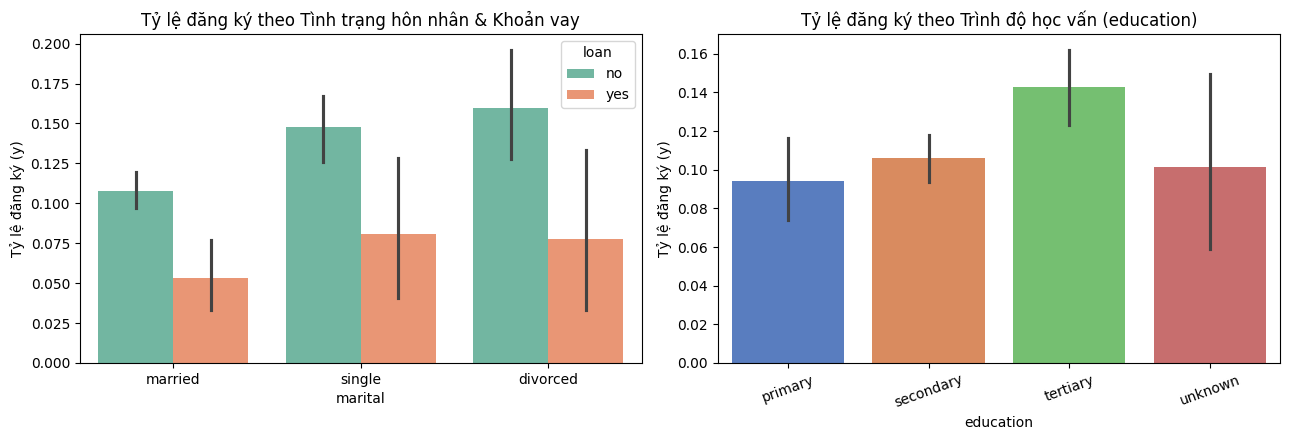

In [8]:
# Câu 4
print("Phạm Đức Anh - 6451071001")

df['y_num'] = df['y'].map({'no': 0, 'yes': 1})

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(13, 4.5))

# 1. Tỷ lệ đăng ký theo Tình trạng hôn nhân (marital) và Khoản vay (loan)
sns.barplot(x='marital', y='y_num', hue='loan', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Tỷ lệ đăng ký theo Tình trạng hôn nhân & Khoản vay')
axes[0].set_ylabel('Tỷ lệ đăng ký (y)')

# 2. Tỷ lệ đăng ký theo Trình độ học vấn (education)
sns.barplot(x='education', y='y_num', data=df, ax=axes[1], palette='muted')
axes[1].set_title('Tỷ lệ đăng ký theo Trình độ học vấn (education)')
axes[1].set_ylabel('Tỷ lệ đăng ký (y)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

# Xóa cột tạm sau khi vẽ xong
df = df.drop(['y_num'], axis=1)

In [9]:
# Câu 5
print("Phạm Đức Anh - 6451071001")

# Đọc lại dữ liệu gốc để tránh lỗi KeyError nếu chạy lại cell nhiều lần
df = pd.read_csv('bank.csv', sep=';')

# 1. Chuyển 'unknown' thành NaN ở các cột cần xử lý
df = df.replace('unknown', np.nan)

# 2. Xóa các cột thiếu quá nhiều dữ liệu hoặc không cần thiết (poutcome, contact, day, month)
df = df.drop(['poutcome', 'contact', 'day', 'month'], axis=1)

# 3. Điền giá trị thiếu cho 'job' và 'education' bằng giá trị phổ biến nhất (mode)
df['job'] = df['job'].fillna(df['job'].mode()[0])
df['education'] = df['education'].fillna(df['education'].mode()[0])

print("--- Kiểm tra lại số lượng giá trị thiếu sau tiền xử lý ---")
print(df.isnull().sum())
df.head(10)

Phạm Đức Anh - 6451071001
--- Kiểm tra lại số lượng giá trị thiếu sau tiền xử lý ---
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
duration     0
campaign     0
pdays        0
previous     0
y            0
dtype: int64


,age,job,marital,education,default,balance,housing,loan,duration,campaign,pdays,previous,y
0,30,unemployed,married,primary,no,1787,no,no,79,1,-1,0,no
1,33,services,married,secondary,no,4789,yes,yes,220,1,339,4,no
2,35,management,single,tertiary,no,1350,yes,no,185,1,330,1,no
3,30,management,married,tertiary,no,1476,yes,yes,199,4,-1,0,no
4,59,blue-collar,married,secondary,no,0,yes,no,226,1,-1,0,no
5,35,management,single,tertiary,no,747,no,no,141,2,176,3,no
6,36,self-employed,married,tertiary,no,307,yes,no,341,1,330,2,no
7,39,technician,married,secondary,no,147,yes,no,151,2,-1,0,no
8,41,entrepreneur,married,tertiary,no,221,yes,no,57,2,-1,0,no
9,43,services,married,primary,no,-88,yes,yes,313,1,147,2,no


In [10]:
# Câu 6
print("Phạm Đức Anh - 6451071001")

# 1. Chuyển đổi các thuộc tính nhị phân sang 0 và 1
binary_cols = ['y', 'default', 'housing', 'loan']
for col in binary_cols:
    df[col] = df[col].map({'no': 0, 'yes': 1})

# 2. Chuyển đổi Tình trạng hôn nhân (marital) sang số
df['marital'] = df['marital'].map({'single': 0, 'married': 1, 'divorced': 2})

# 3. Chuyển đổi Trình độ học vấn (education) theo thứ bậc
edu_map = {'primary': 1, 'secondary': 2, 'tertiary': 3}
df['education'] = df['education'].map(edu_map)

# 4. Chuyển đổi Nghề nghiệp (job) sang mã số nguyên
job_map = {job: idx for idx, job in enumerate(df['job'].unique())}
df['job'] = df['job'].map(job_map)

# 5. Rời rạc hóa Tuổi (age) thành 5 nhóm (0 đến 4)
df.loc[df['age'] <= 25, 'age'] = 0
df.loc[(df['age'] > 25) & (df['age'] <= 35), 'age'] = 1
df.loc[(df['age'] > 35) & (df['age'] <= 45), 'age'] = 2
df.loc[(df['age'] > 45) & (df['age'] <= 60), 'age'] = 3
df.loc[df['age'] > 60, 'age'] = 4

# 6. Rời rạc hóa Thời lượng cuộc gọi (duration) thành 4 nhóm (0 đến 3)
df.loc[df['duration'] <= 150, 'duration'] = 0
df.loc[(df['duration'] > 150) & (df['duration'] <= 300), 'duration'] = 1
df.loc[(df['duration'] > 300) & (df['duration'] <= 600), 'duration'] = 2
df.loc[df['duration'] > 600, 'duration'] = 3

# 7. Tạo thuộc tính mới (Feature Engineering): tương tác giữa nhóm duration và số lần liên hệ (campaign)
df['duration_per_campaign'] = (df['duration'] / df['campaign']).round(2)

print("--- Kiểm tra thông tin bảng dữ liệu sau cùng ---")
df.info()
df.head(10)

Phạm Đức Anh - 6451071001
--- Kiểm tra thông tin bảng dữ liệu sau cùng ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    4521 non-null   int64  
 1   job                    4521 non-null   int64  
 2   marital                4521 non-null   int64  
 3   education              4521 non-null   int64  
 4   default                4521 non-null   int64  
 5   balance                4521 non-null   int64  
 6   housing                4521 non-null   int64  
 7   loan                   4521 non-null   int64  
 8   duration               4521 non-null   int64  
 9   campaign               4521 non-null   int64  
 10  pdays                  4521 non-null   int64  
 11  previous               4521 non-null   int64  
 12  y                      4521 non-null   int64  
 13  duration_per_campaign  4521 non-n

,age,job,marital,education,default,balance,housing,loan,duration,campaign,pdays,previous,y,duration_per_campaign
0,1,0,1,1,0,1787,0,0,0,1,-1,0,0,0.00
1,1,1,1,2,0,4789,1,1,1,1,339,4,0,1.00
2,1,2,0,3,0,1350,1,0,1,1,330,1,0,1.00
3,1,2,1,3,0,1476,1,1,1,4,-1,0,0,0.25
4,3,3,1,2,0,0,1,0,1,1,-1,0,0,1.00
5,1,2,0,3,0,747,0,0,0,2,176,3,0,0.00
6,2,4,1,3,0,307,1,0,2,1,330,2,0,2.00
7,2,5,1,2,0,147,1,0,1,2,-1,0,0,0.50
8,2,6,1,3,0,221,1,0,0,2,-1,0,0,0.00
9,2,1,1,1,0,-88,1,1,2,1,147,2,0,2.00
